findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: 

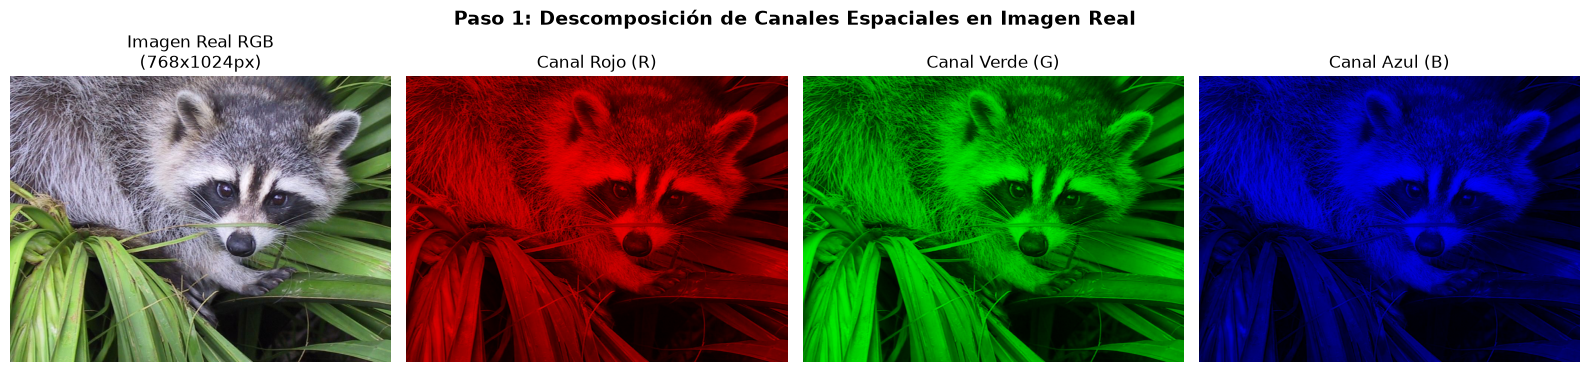

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: 

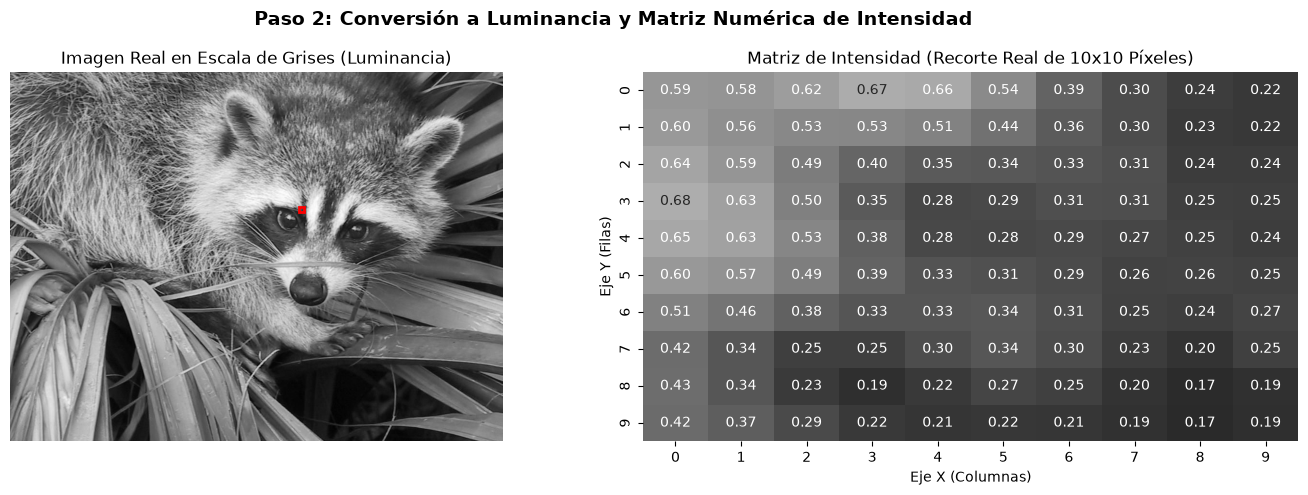

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: 

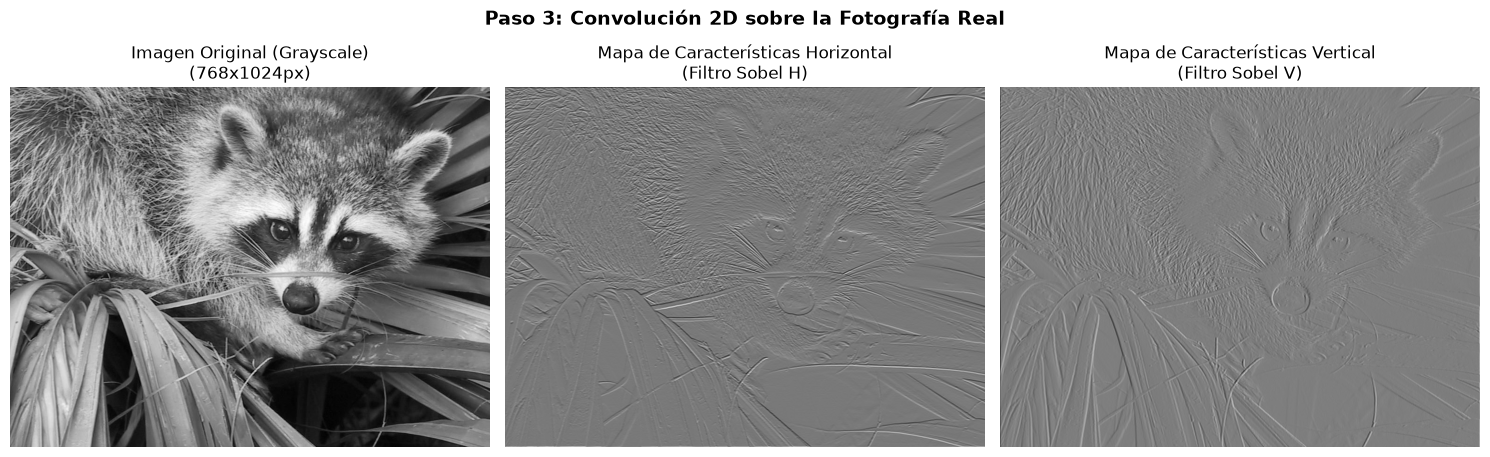

findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: Generic family 'sans-serif' not found because none of the following families were found: sans-serif
findfont: 

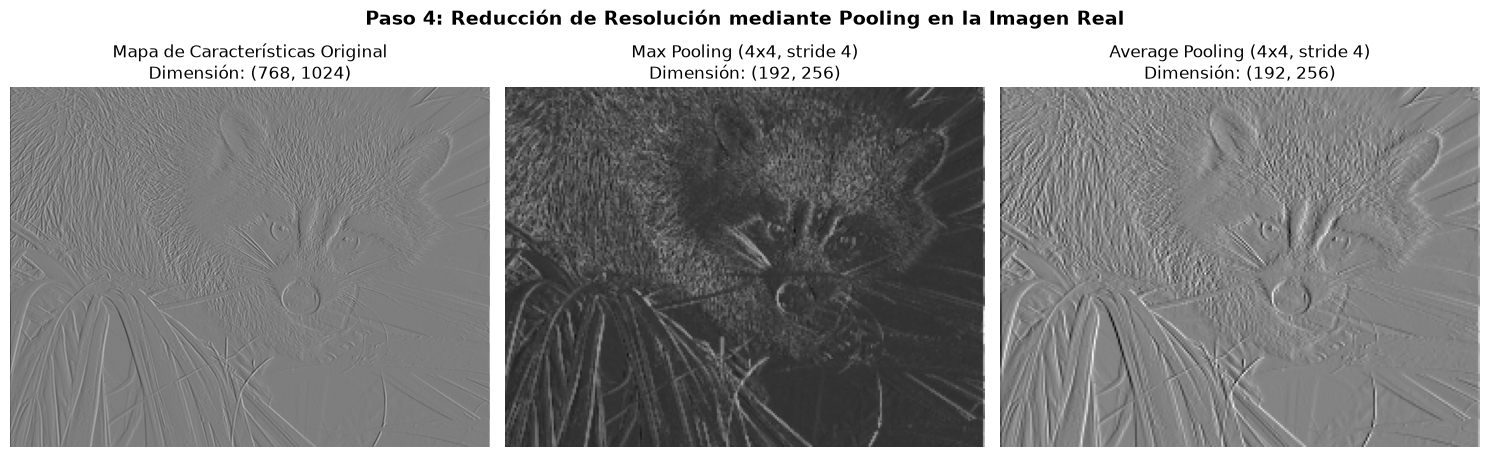

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import convolve2d
from scipy.datasets import face

# Configuración estética
plt.style.use('default')
plt.rcParams['font.sans-serif'] = 'sans-serif'
plt.rcParams['font.size'] = 10

# ==========================================
# 1. CARGA DE IMAGEN REAL (RGB)
# ==========================================
# Cargar imagen real (Fotografía a color de 768 x 1024 píxeles)
img_rgb = face().astype(np.float32) / 255.0  # Normalización [0.0, 1.0]

# ==========================================
# 2. DESCOMPOSICIÓN EN CANALES RGB
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_rgb)
axes[0].set_title(f"Imagen Real RGB\n({img_rgb.shape[0]}x{img_rgb.shape[1]}px)")
axes[0].axis('off')

# Canal Rojo (mantener solo canal 0)
img_r = img_rgb.copy()
img_r[:, :, [1, 2]] = 0
axes[1].imshow(img_r)
axes[1].set_title("Canal Rojo (R)")
axes[1].axis('off')

# Canal Verde (mantener solo canal 1)
img_g = img_rgb.copy()
img_g[:, :, [0, 2]] = 0
axes[2].imshow(img_g)
axes[2].set_title("Canal Verde (G)")
axes[2].axis('off')

# Canal Azul (mantener solo canal 2)
img_b = img_rgb.copy()
img_b[:, :, [0, 1]] = 0
axes[3].imshow(img_b)
axes[3].set_title("Canal Azul (B)")
axes[3].axis('off')

plt.suptitle("Paso 1: Descomposición de Canales Espaciales en Imagen Real", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 3. ESCALA DE GRISES E INTENSIDAD DE LUZ
# ==========================================
# Luminancia estándar ITU-R BT.601: Y = 0.2989 R + 0.5870 G + 0.1140 B
img_gray = 0.2989 * img_rgb[:, :, 0] + 0.5870 * img_rgb[:, :, 1] + 0.1140 * img_rgb[:, :, 2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Visualización completa
im1 = ax1.imshow(img_gray, cmap='gray')
ax1.set_title("Imagen Real en Escala de Grises (Luminancia)")
ax1.axis('off')

# Dibujar un recuadro rojo indicando la región recortada
rect = plt.Rectangle((600, 280), 10, 10, edgecolor='red', facecolor='none', lw=2)
ax1.add_patch(rect)

# Recorte de una submatriz real de 10x10 píxeles
submatriz = img_gray[280:290, 600:610]
sns.heatmap(submatriz, annot=True, fmt=".2f", cmap="gray", cbar=False, ax=ax2, vmin=0, vmax=1)
ax2.set_title("Matriz de Intensidad (Recorte Real de 10x10 Píxeles)")
ax2.set_xlabel("Eje X (Columnas)")
ax2.set_ylabel("Eje Y (Filas)")

plt.suptitle("Paso 2: Conversión a Luminancia y Matriz Numérica de Intensidad", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 4. OPERACIÓN DE CONVOLUCIÓN 2D (FILTRADO DE BORDES)
# ==========================================
# Kernels Sobel para detección de bordes
kernel_sobel_h = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

kernel_sobel_v = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

# Convolución discreta 2D
feature_map_h = convolve2d(img_gray, kernel_sobel_h, mode='same')
feature_map_v = convolve2d(img_gray, kernel_sobel_v, mode='same')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title(f"Imagen Original (Grayscale)\n({img_gray.shape[0]}x{img_gray.shape[1]}px)")
axes[0].axis('off')

axes[1].imshow(feature_map_h, cmap='gray')
axes[1].set_title("Mapa de Características Horizontal\n(Filtro Sobel H)")
axes[1].axis('off')

axes[2].imshow(feature_map_v, cmap='gray')
axes[2].set_title("Mapa de Características Vertical\n(Filtro Sobel V)")
axes[2].axis('off')

plt.suptitle("Paso 3: Convolución 2D sobre la Fotografía Real", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 5. SUBMUESTREO ESPACIAL (POOLING)
# ==========================================
def max_pooling(matriz, pool_size=4, stride=4):
    H, W = matriz.shape
    out_h = (H - pool_size) // stride + 1
    out_w = (W - pool_size) // stride + 1
    pooled = np.zeros((out_h, out_w))
    
    for i in range(out_h):
        for j in range(out_w):
            slice_region = matriz[i*stride : i*stride + pool_size, j*stride : j*stride + pool_size]
            pooled[i, j] = np.max(slice_region)
            
    return pooled

def avg_pooling(matriz, pool_size=4, stride=4):
    H, W = matriz.shape
    out_h = (H - pool_size) // stride + 1
    out_w = (W - pool_size) // stride + 1
    pooled = np.zeros((out_h, out_w))
    
    for i in range(out_h):
        for j in range(out_w):
            slice_region = matriz[i*stride : i*stride + pool_size, j*stride : j*stride + pool_size]
            pooled[i, j] = np.mean(slice_region)
            
    return pooled

# Aplicar Pooling con ventana de 4x4 y stride 4
img_max_pool = max_pooling(feature_map_v, pool_size=4, stride=4)
img_avg_pool = avg_pooling(feature_map_v, pool_size=4, stride=4)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(feature_map_v, cmap='gray')
axes[0].set_title(f"Mapa de Características Original\nDimensión: {feature_map_v.shape}")
axes[0].axis('off')

axes[1].imshow(img_max_pool, cmap='gray')
axes[1].set_title(f"Max Pooling (4x4, stride 4)\nDimensión: {img_max_pool.shape}")
axes[1].axis('off')

axes[2].imshow(img_avg_pool, cmap='gray')
axes[2].set_title(f"Average Pooling (4x4, stride 4)\nDimensión: {img_avg_pool.shape}")
axes[2].axis('off')

plt.suptitle("Paso 4: Reducción de Resolución mediante Pooling en la Imagen Real", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()